<a href="https://colab.research.google.com/github/hasanjim-dev/ml-learning/blob/main/kmeans-pca/kmeans-pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("/content/Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [11]:
df['Genre'].value_counts()

,count
Genre,
Female,112
Male,88


In [24]:
print("Dataset Info:")
df.info()

print("Summary Statistics:")
print(df.describe())

print("Missing values:")
print(df.isnull().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
Summary Statistics:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50% 

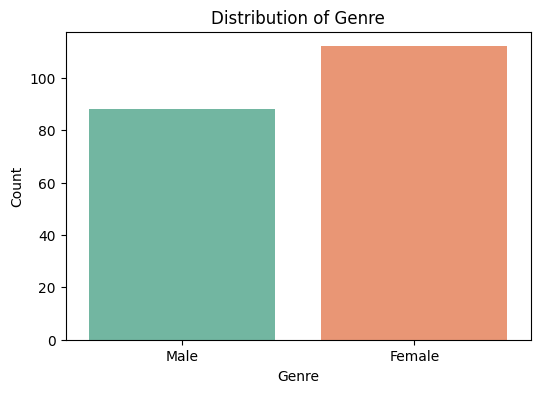

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Genre', hue='Genre', palette='Set2', legend=False)
plt.title('Distribution of Genre')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.show()

In [17]:
import plotly.express as px

# Count the occurrences of each genre
genre_counts = df['Genre'].value_counts().reset_index()
genre_counts.columns = ['Genre', 'Count']

# Create an interactive bar plot
fig = px.bar(
    genre_counts,
    x='Genre',
    y='Count',
    color='Genre',
    color_discrete_sequence=px.colors.qualitative.Set2,
    title='Distribution of Genre (Interactive)'
)
fig.show()

In [20]:
df['Spending Score (1-100)']

,Spending Score (1-100)
0,39
1,81
2,6
3,77
4,40
...,...
195,79
196,28
197,74
198,18


In [21]:
df['Spending Score (1-100)'].value_counts()

,count
Spending Score (1-100),
42,8
55,7
73,6
46,6
48,5
...,...
68,1
85,1
23,1


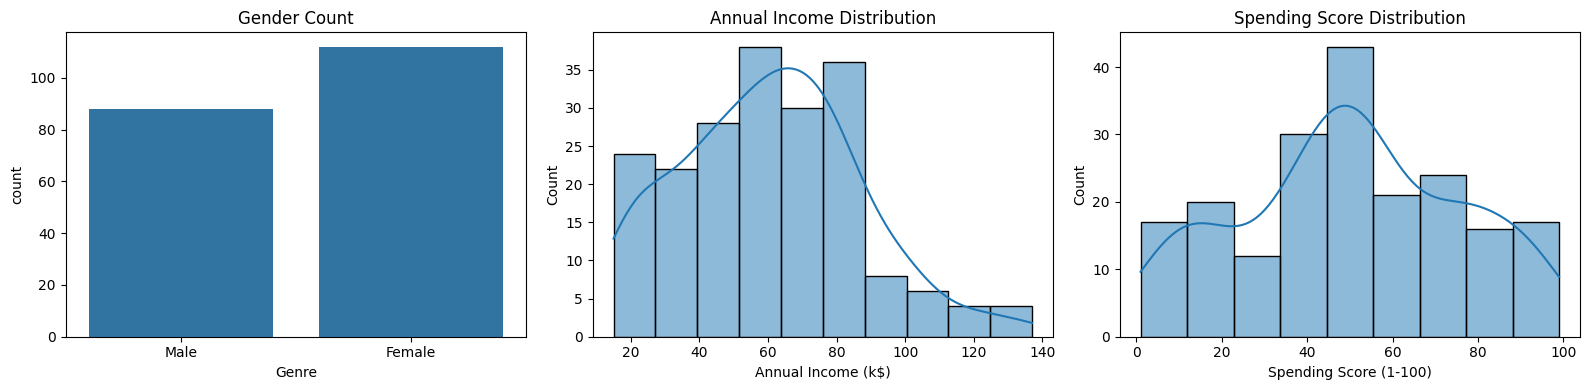

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x='Genre', data=df, ax=axes[0])
axes[0].set_title('Gender Count')

sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[1])
axes[1].set_title('Annual Income Distribution')

sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[2])
axes[2].set_title('Spending Score Distribution')

plt.tight_layout()
plt.show()

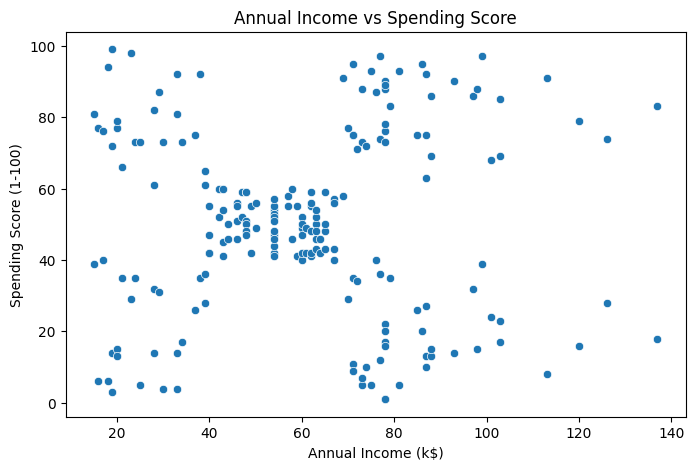

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=df)
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

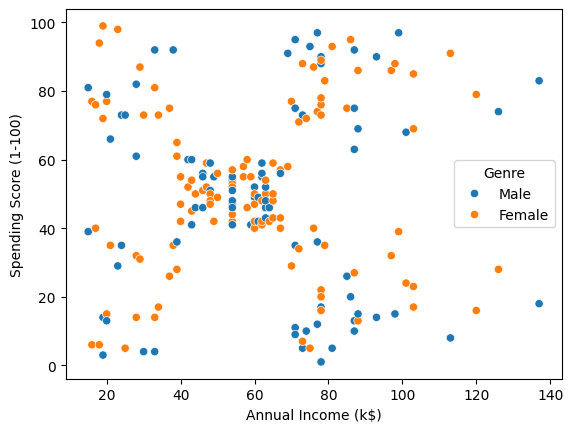

In [23]:
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Genre', data=df)

k-Means distance scalling

In [26]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scaling (StandardScaler: mean = 0, std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


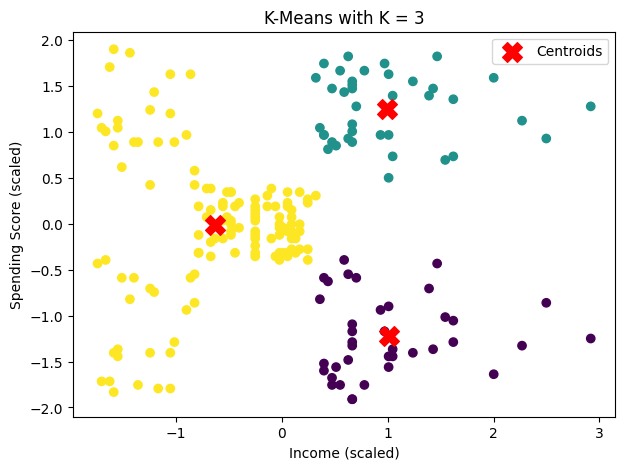

In [27]:
kmeans_demo = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_demo = kmeans_demo.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_demo, cmap='viridis')
plt.scatter(kmeans_demo.cluster_centers_[:, 0], kmeans_demo.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroids')
plt.title('K-Means with K = 3')
plt.xlabel('Income (scaled)')
plt.ylabel('Spending Score (scaled)')
plt.legend()
plt.show()

Elbow Method

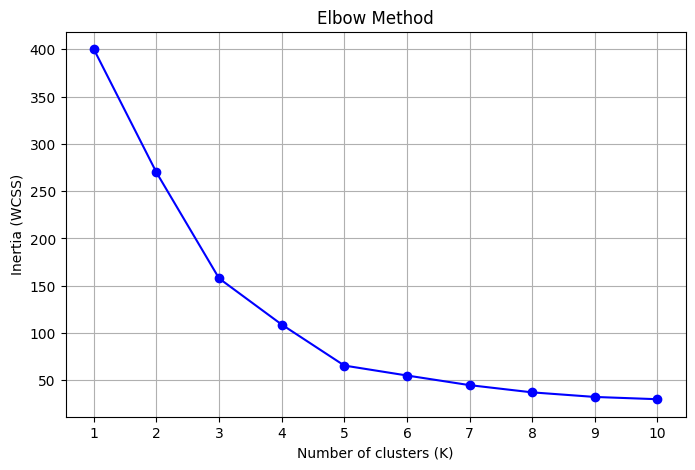

In [28]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [32]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    print(f"K = {k}  ->  Silhouette Score = {silhouette_score(X_scaled, lbl):.3f}")

K = 2  ->  Silhouette Score = 0.321
K = 3  ->  Silhouette Score = 0.467
K = 4  ->  Silhouette Score = 0.494
K = 5  ->  Silhouette Score = 0.555
K = 6  ->  Silhouette Score = 0.540
K = 7  ->  Silhouette Score = 0.528
K = 8  ->  Silhouette Score = 0.455
K = 9  ->  Silhouette Score = 0.457
K = 10  ->  Silhouette Score = 0.443


optimal K = 5

In [33]:
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


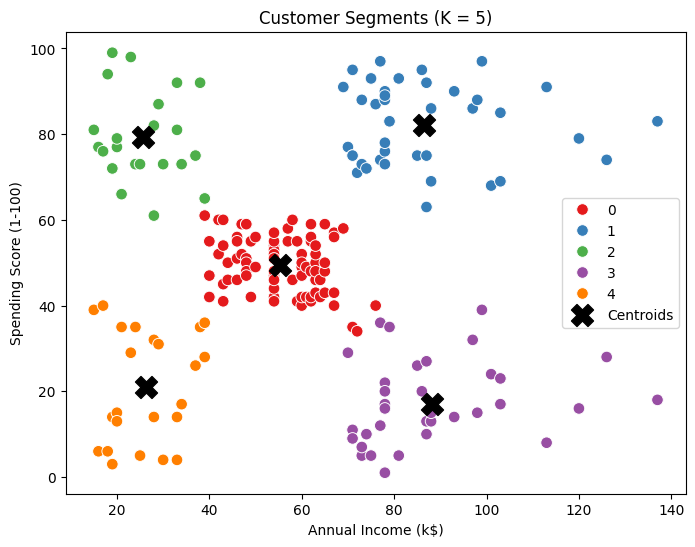

In [38]:
# Cluster visualization (original scale)
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='Set1', data=df, s=70)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=250, label='Centroids')
plt.title(f'Customer Segments (K = {optimal_k})')
plt.legend()
plt.show()

In [39]:
df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.7,55.3,49.5
1,32.7,86.5,82.1
2,25.3,25.7,79.4
3,41.1,88.2,17.1
4,45.2,26.3,20.9


PCA

In [40]:
features = df[['Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']].copy()
features = pd.get_dummies(features, columns=['Genre'], drop_first=True)
features = features.astype(float)

X_all_scaled = StandardScaler().fit_transform(features)
print(features.columns.tolist())

['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Genre_Male']


Explained variance ratio: [0.337 0.262 0.233 0.168]
Cumulative variance     : [0.337 0.599 0.832 1.   ]


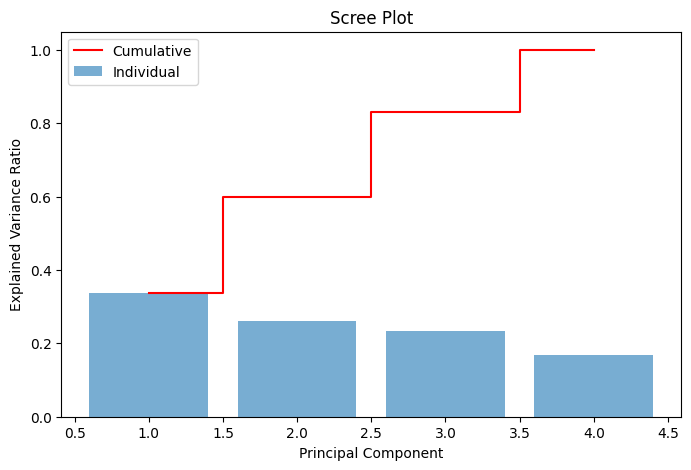

In [41]:
pca_full = PCA()
pca_full.fit(X_all_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("Explained variance ratio:", np.round(explained, 3))
print("Cumulative variance     :", np.round(cumulative, 3))

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(explained) + 1), explained, alpha=0.6, label='Individual')
plt.step(range(1, len(cumulative) + 1), cumulative, where='mid', color='red', label='Cumulative')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.legend()
plt.show()

In [42]:
# 2টা component-এ কমিয়ে আনা (4D -> 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all_scaled)

df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

print("Original shape:", X_all_scaled.shape)
print("Reduced shape :", X_pca.shape)
print("Total variance kept:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Original shape: (200, 4)
Reduced shape : (200, 2)
Total variance kept: 59.92 %
